In [2]:
install.packages("reticulate", repos = "https://cloud.r-project.org")


also installing the dependencies ‘RcppTOML’, ‘png’





The downloaded binary packages are in
	/var/folders/_r/w52qnsrn2g303dmlc8vv14nr0000gn/T//RtmpesfO1Q/downloaded_packages


In [4]:
library(reticulate)
py_install("kagglehub", pip = TRUE)

kagglehub <- import("kagglehub")

path <- kagglehub$dataset_download("mobeenfatimah/diabetes-risk-prediction-dataset-50k-patients")
cat("Downloaded to:", path, "\n")

dir.create("data", showWarnings = FALSE)
csv_files <- list.files(path, pattern = "\\.csv$", full.names = TRUE)
file.copy(csv_files, "data", overwrite = TRUE)

print(list.files("data", pattern = "\\.csv$", full.names = TRUE))

Using Python: /usr/bin/python3
Creating virtual environment '~/.virtualenvs/r-reticulate' ... 


+ /usr/bin/python3 -m venv /Users/nkki/.virtualenvs/r-reticulate



Done!
Installing packages: pip, wheel, setuptools


+ /Users/nkki/.virtualenvs/r-reticulate/bin/python -m pip install --upgrade pip wheel setuptools



Virtual environment '~/.virtualenvs/r-reticulate' successfully created.
Using virtual environment '~/.virtualenvs/r-reticulate' ...


+ /Users/nkki/.virtualenvs/r-reticulate/bin/python -m pip install --upgrade --no-user kagglehub

Warning message:
“Some Python package requirements declared via `py_require()` are not installed in the selected Python environment: (/Users/nkki/.virtualenvs/r-reticulate/bin/python)
  numpy”


Downloaded to: /Users/nkki/.cache/kagglehub/datasets/mobeenfatimah/diabetes-risk-prediction-dataset-50k-patients/versions/1 


[1] TRUE

[1] "data/diabetes_risk_prediction_dataset.csv"


In [6]:
install.packages(c("janitor", "readr", "dplyr"), repos = "https://cloud.r-project.org")


The downloaded binary packages are in
	/var/folders/_r/w52qnsrn2g303dmlc8vv14nr0000gn/T//RtmpesfO1Q/downloaded_packages


In [7]:
library(readr)    
library(janitor)  
library(dplyr) 
df <- read_csv("data/diabetes_risk_prediction_dataset.csv", show_col_types = FALSE) |>
  clean_names()     
dim(df)
glimpse(df)


Attaching package: ‘janitor’


The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




[1] 50000    41

Rows: 50,000
Columns: 41
$ patient_id                 <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, …
$ age                        <dbl> 32, 42, 89, 87, 27, 29, 90, 80, 40, 73, 77,…
$ gender                     <chr> "Male", "Other", "Other", "Other", "Other",…
$ country                    <chr> "Mexico", "Saudi Arabia", "Argentina", "Uni…
$ height_cm                  <dbl> 182.1, 148.5, 158.1, 190.9, 156.9, 153.3, 1…
$ weight_kg                  <dbl> 65.8, 101.2, NA, 95.9, 101.9, 86.3, 67.2, 1…
$ bmi                        <dbl> 19.8, 45.9, 37.9, 26.3, 41.4, 36.7, 26.0, 3…
$ waist_circumference_cm     <dbl> 71.2, 121.8, 131.8, 99.1, 77.1, 77.1, 113.6…
$ blood_glucose              <dbl> 88.4, 247.3, 141.9, 90.1, 93.8, 142.2, 126.…
$ hb_a1c                     <dbl> 10.4, 11.3, 6.3, 7.4, 12.0, 5.0, 6.6, 6.7, …
$ fasting_blood_sugar        <dbl> 149.5, 199.3, 219.6, 217.7, 153.5, 123.7, 8…
$ insulin_level              <dbl> 27.4, 18.3, 23.9, 36.7, 22.3, 44.4, 29.8, 3…
$ blood_pressur

In [8]:
target <- "diabetes_risk"

if (!target %in% names(df)) {
  stop("Target not found. Columns are: ", paste(names(df), collapse = ", "))
}

In [10]:
install.packages(c("tidyr", "skimr"), repos = "https://cloud.r-project.org")


The downloaded binary packages are in
	/var/folders/_r/w52qnsrn2g303dmlc8vv14nr0000gn/T//RtmpesfO1Q/downloaded_packages


In [11]:
library(dplyr)
library(tidyr)   
library(skimr)
#data quality check
cat("Duplicate rows:", sum(duplicated(df)), "\n\n")

#missing values per column
missing_tbl <- df |>
  summarise(across(everything(), ~ sum(is.na(.)))) |>
  pivot_longer(everything(), names_to = "column", values_to = "n_missing") |>
  mutate(pct_missing = round(100 * n_missing / nrow(df), 2)) |>
  arrange(desc(n_missing))

print(missing_tbl |> filter(n_missing > 0))
if (all(missing_tbl$n_missing == 0)) cat("No missing values.\n")

skim(df)

Duplicate rows: 0 

# A tibble: 14 × 3
   column                  n_missing pct_missing
   <chr>                       <int>       <dbl>
 1 weight_kg                    2962        5.92
 2 height_cm                    2945        5.89
 3 sleep_hours                  2017        4.03
 4 exercise_hours_per_week      1992        3.98
 5 hb_a1c                       1974        3.95
 6 daily_walking_minutes        1964        3.93
 7 total_cholesterol            1000        2   
 8 hdl                          1000        2   
 9 ldl                          1000        2   
10 triglycerides                1000        2   
11 medication_adherence         1000        2   
12 blood_glucose                 959        1.92
13 physical_activity_level       500        1   
14 age                           497        0.99


,skim_type,skim_variable,n_missing,complete_rate,character.min,character.max,character.empty,character.n_unique,character.whitespace,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,character,gender,0,1.00000,4,6,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
2,character,country,0,1.00000,5,14,0,25,0,NA,NA,NA,NA,NA,NA,NA,NA
3,character,physical_activity_level,500,0.99000,3,8,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
4,character,diet_quality,0,1.00000,4,7,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
5,character,sugar_intake_level,0,1.00000,3,8,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
6,character,stress_level,0,1.00000,3,8,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
7,character,smoking_status,0,1.00000,5,7,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
8,character,alcohol_consumption,0,1.00000,5,12,0,3,0,NA,NA,NA,NA,NA,NA,NA,NA
9,character,family_history_diabetes,0,1.00000,2,3,0,2,0,NA,NA,NA,NA,NA,NA,NA,NA


In [12]:
#data types
cat("\nData types:\n")
print(df |> summarise(across(everything(), ~ class(.))) |>
  pivot_longer(everything(), names_to = "column", values_to = "data_type"))      


Data types:
# A tibble: 41 × 2
   column                 data_type
   <chr>                  <chr>    
 1 patient_id             numeric  
 2 age                    numeric  
 3 gender                 character
 4 country                character
 5 height_cm              numeric  
 6 weight_kg              numeric  
 7 bmi                    numeric  
 8 waist_circumference_cm numeric  
 9 blood_glucose          numeric  
10 hb_a1c                 numeric  
# ℹ 31 more rows


In [ ]:
#data cleaning

In [14]:
install.packages(c("ggplot2", "scales"), repos = "https://cloud.r-project.org")


The downloaded binary packages are in
	/var/folders/_r/w52qnsrn2g303dmlc8vv14nr0000gn/T//RtmpesfO1Q/downloaded_packages



Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor




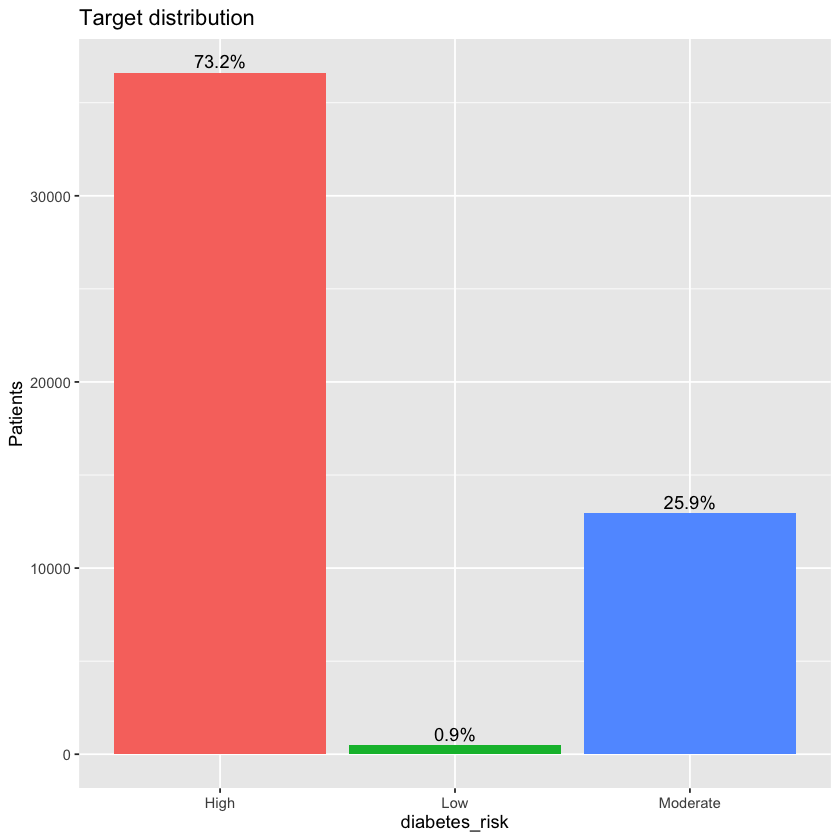

In [15]:
library(ggplot2)
library(scales)   
library(dplyr)
#target distribution
df |>
  count(.data[[target]]) |>
  mutate(pct = n / sum(n)) |>
  ggplot(aes(x = .data[[target]], y = n, fill = .data[[target]])) +
  geom_col(show.legend = FALSE) +
  geom_text(aes(label = percent(pct, accuracy = 0.1)), vjust = -0.4) +
  labs(title = "Target distribution", x = target, y = "Patients")

#### Target Distribution (`diabetes_risk`)

**Observations**
- The target is a **categorical variable** with severe **class imbalance**: High 73.2%, Moderate 25.9%, Low 0.9% (about 450 patients).
- A model that always predicts "High" would reach about 73% accuracy without learning anything, so accuracy alone is misleading.
- The "Low" class is too small for a model to learn reliably.

**Next steps**
- Set the class order to Low < Moderate < High.
- Use a **stratified** train/test split so every class appears in both sets.
- Evaluate with **macro-F1, per-class recall, and the confusion matrix** instead of accuracy.
- Use `class_weight = "balanced"`, or oversample on the **training set only**.
- Consider merging Low and Moderate into a binary target (High vs Not High) if "Low" remains unpredictable, and justify this in the report.

In [16]:
#summary statistics for numeric columns
num_cols <- df |> select(where(is.numeric)) |> names()
cat_cols <- df |> select(where(is.factor)) |> names() |> setdiff(target)

df |>
  select(all_of(num_cols)) |>
  summarise(across(everything(), list(
    mean   = ~ mean(., na.rm = TRUE),
    sd     = ~ sd(., na.rm = TRUE),
    min    = ~ min(., na.rm = TRUE),
    median = ~ median(., na.rm = TRUE),
    max    = ~ max(., na.rm = TRUE)
  ))) |>
  pivot_longer(everything(),
               names_to = c("feature", "stat"),
               names_pattern = "(.*)_(mean|sd|min|median|max)$") |>
  pivot_wider(names_from = stat, values_from = value) |>
  mutate(across(where(is.numeric), ~ round(., 2)))

feature,mean,sd,min,median,max
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
patient_id,25000.50,14433.90,1.0,25000.5,50000.0
age,53.87,21.13,18.0,54.0,90.0
height_cm,170.02,14.46,145.0,170.0,195.0
weight_kg,87.46,24.50,45.0,87.3,130.0
bmi,30.92,10.29,11.9,30.0,61.7
waist_circumference_cm,99.96,23.09,60.0,99.8,140.0
blood_glucose,159.91,52.04,70.0,159.9,250.0
hb_a1c,8.49,2.31,4.5,8.5,12.5
fasting_blood_sugar,142.61,44.68,65.0,142.6,220.0


Warning message:
“Removed 19310 rows containing non-finite outside the scale range
(`stat_bin()`).”


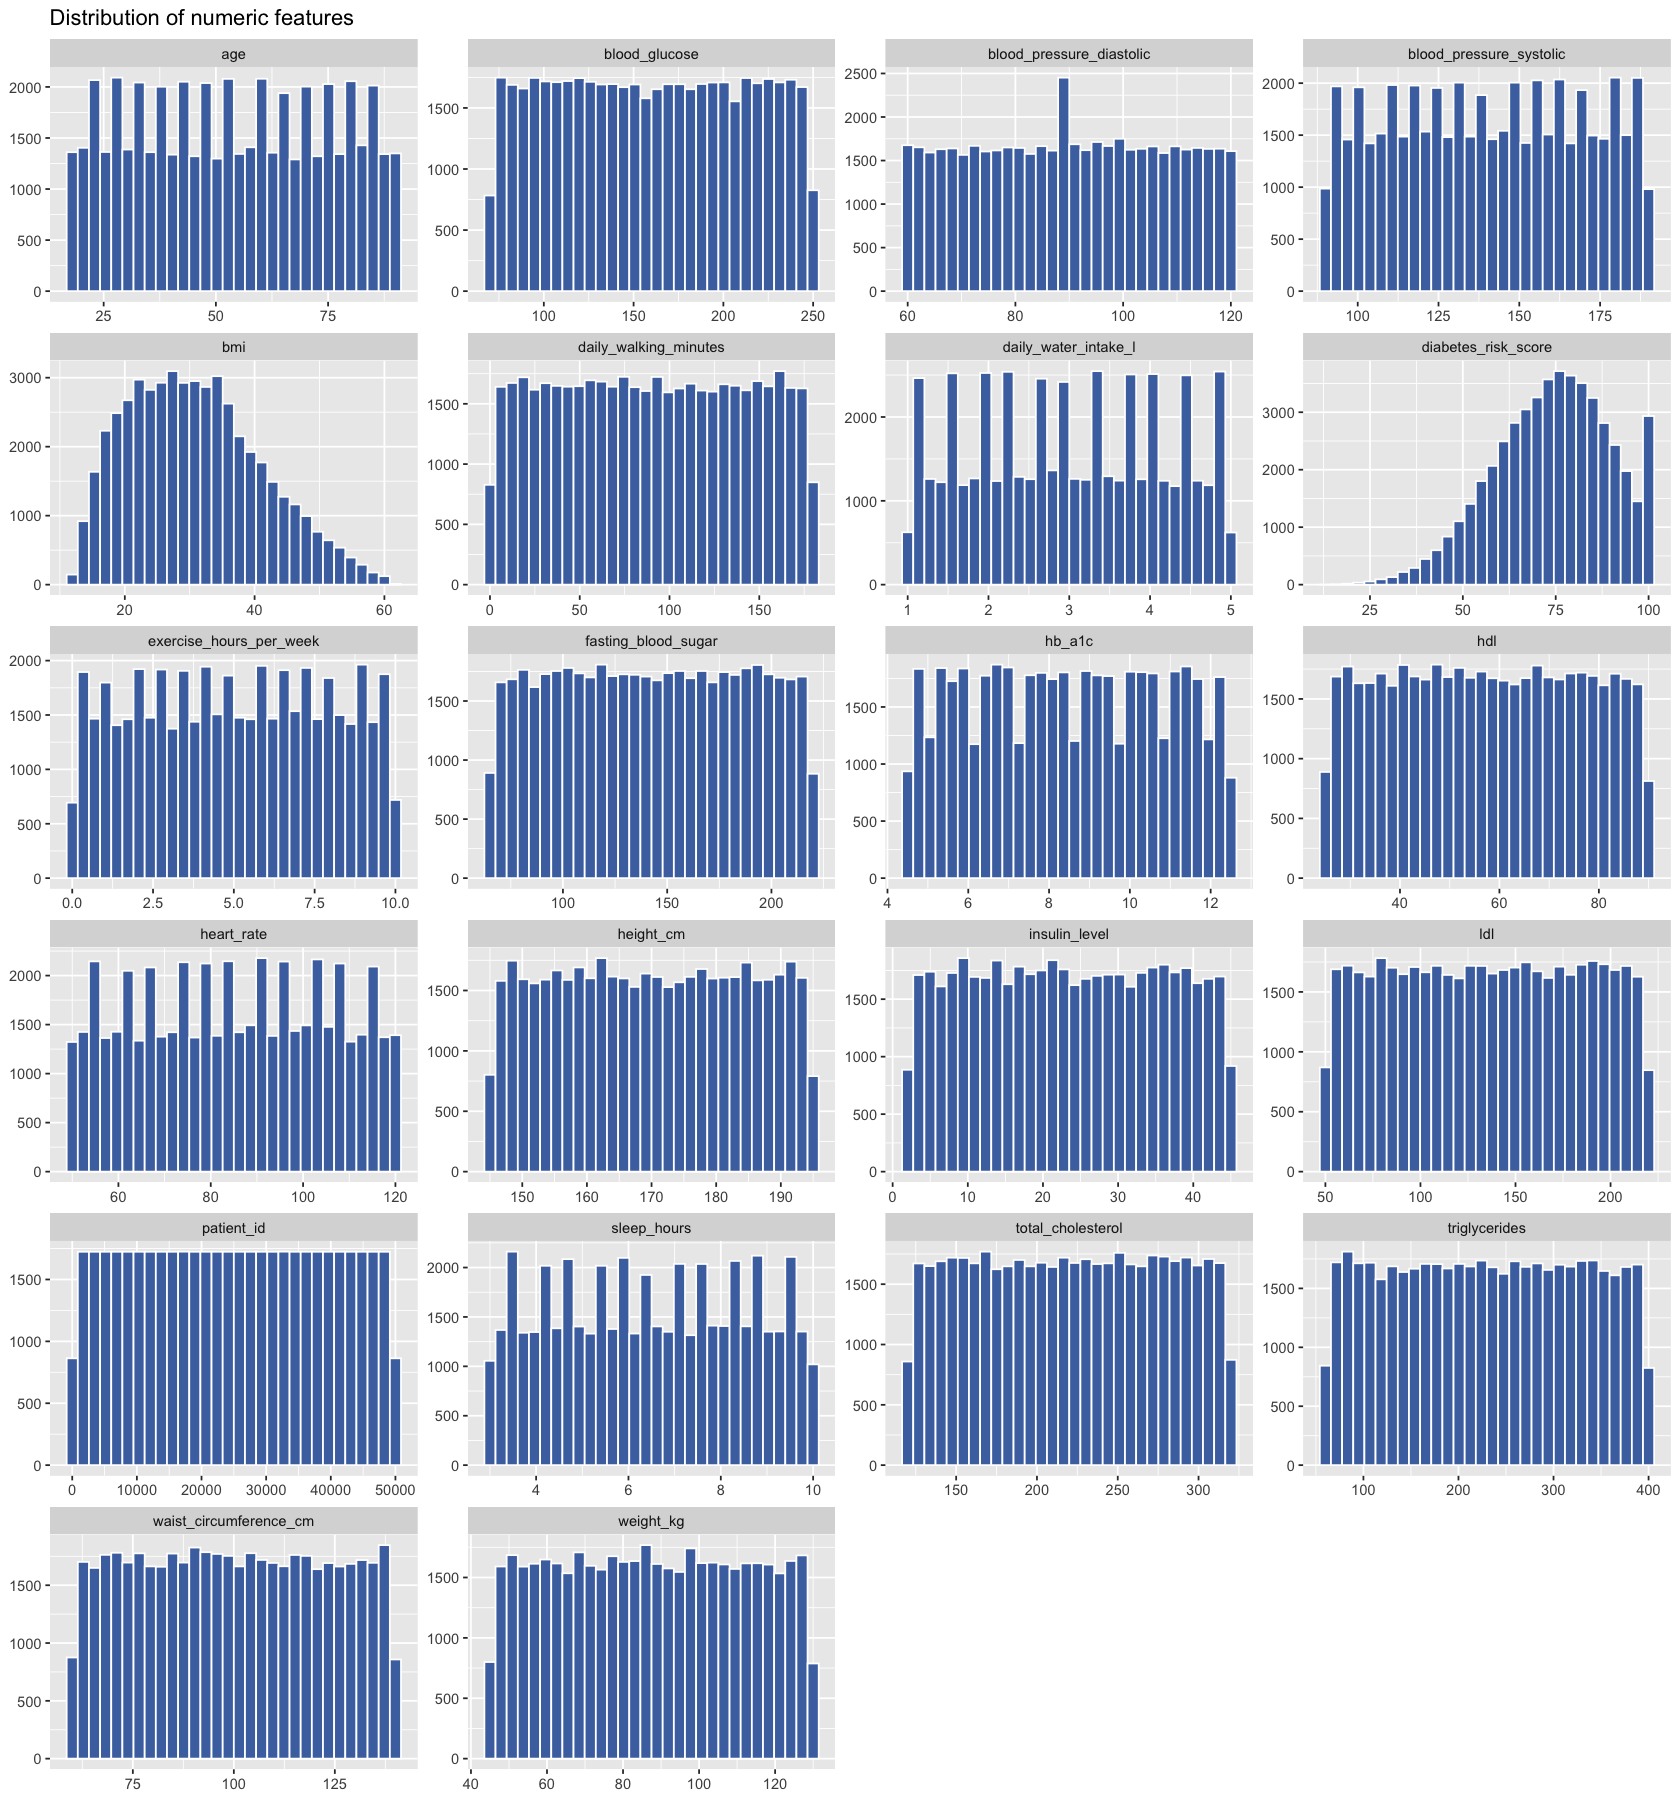

In [17]:
options(repr.plot.width = 14, repr.plot.height = ceiling(length(num_cols) / 4) * 2.5)

df |>
  select(all_of(num_cols)) |>
  pivot_longer(everything(), names_to = "feature", values_to = "value") |>
  ggplot(aes(value)) +
  geom_histogram(bins = 30, fill = "#4c72b0", colour = "white") +
  facet_wrap(~ feature, scales = "free", ncol = 4) +
  labs(title = "Distribution of numeric features", x = NULL, y = NULL)


  #need to replot after removing outliers i.e nulls

#### Distribution of Numeric Features

**Observations**
- Most features (`blood_glucose`, `hb_a1c`, `hdl`, `ldl`, `triglycerides`, `total_cholesterol`, `height_cm`, `weight_kg`, `heart_rate`, `age`, etc.) are roughly **uniformly distributed**, which is typical of synthetic data where each column is sampled independently.
- `bmi` is **right-skewed**, with most values between 20 and 40 and a tail up to about 60.
- `diabetes_risk_score` is **left-skewed**, with most values between 60 and 100 and a spike at 100 (likely capped).
- The comb-like pattern in `age`, `heart_rate`, `blood_pressure_*` and `daily_water_intake_l` is a **binning artifact** from whole-number values, not a real pattern.
- `patient_id` is a unique identifier and carries no predictive information.

**Next steps**
- Drop `patient_id` before analysis and modelling.
- Apply a log transform to `bmi` only if a linear model (e.g. Logistic Regression) is used. Tree-based models don't need it.
- Check whether `diabetes_risk_score` is derived from the target. If it is, remove it to avoid **data leakage**.
- Use `binwidth = 1` for integer columns to remove the artifact.
- Check for impossible values (e.g. BMI below 12, very high glucose) before deciding whether to cap or remove outliers.

Warning message:
“Removed 19310 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


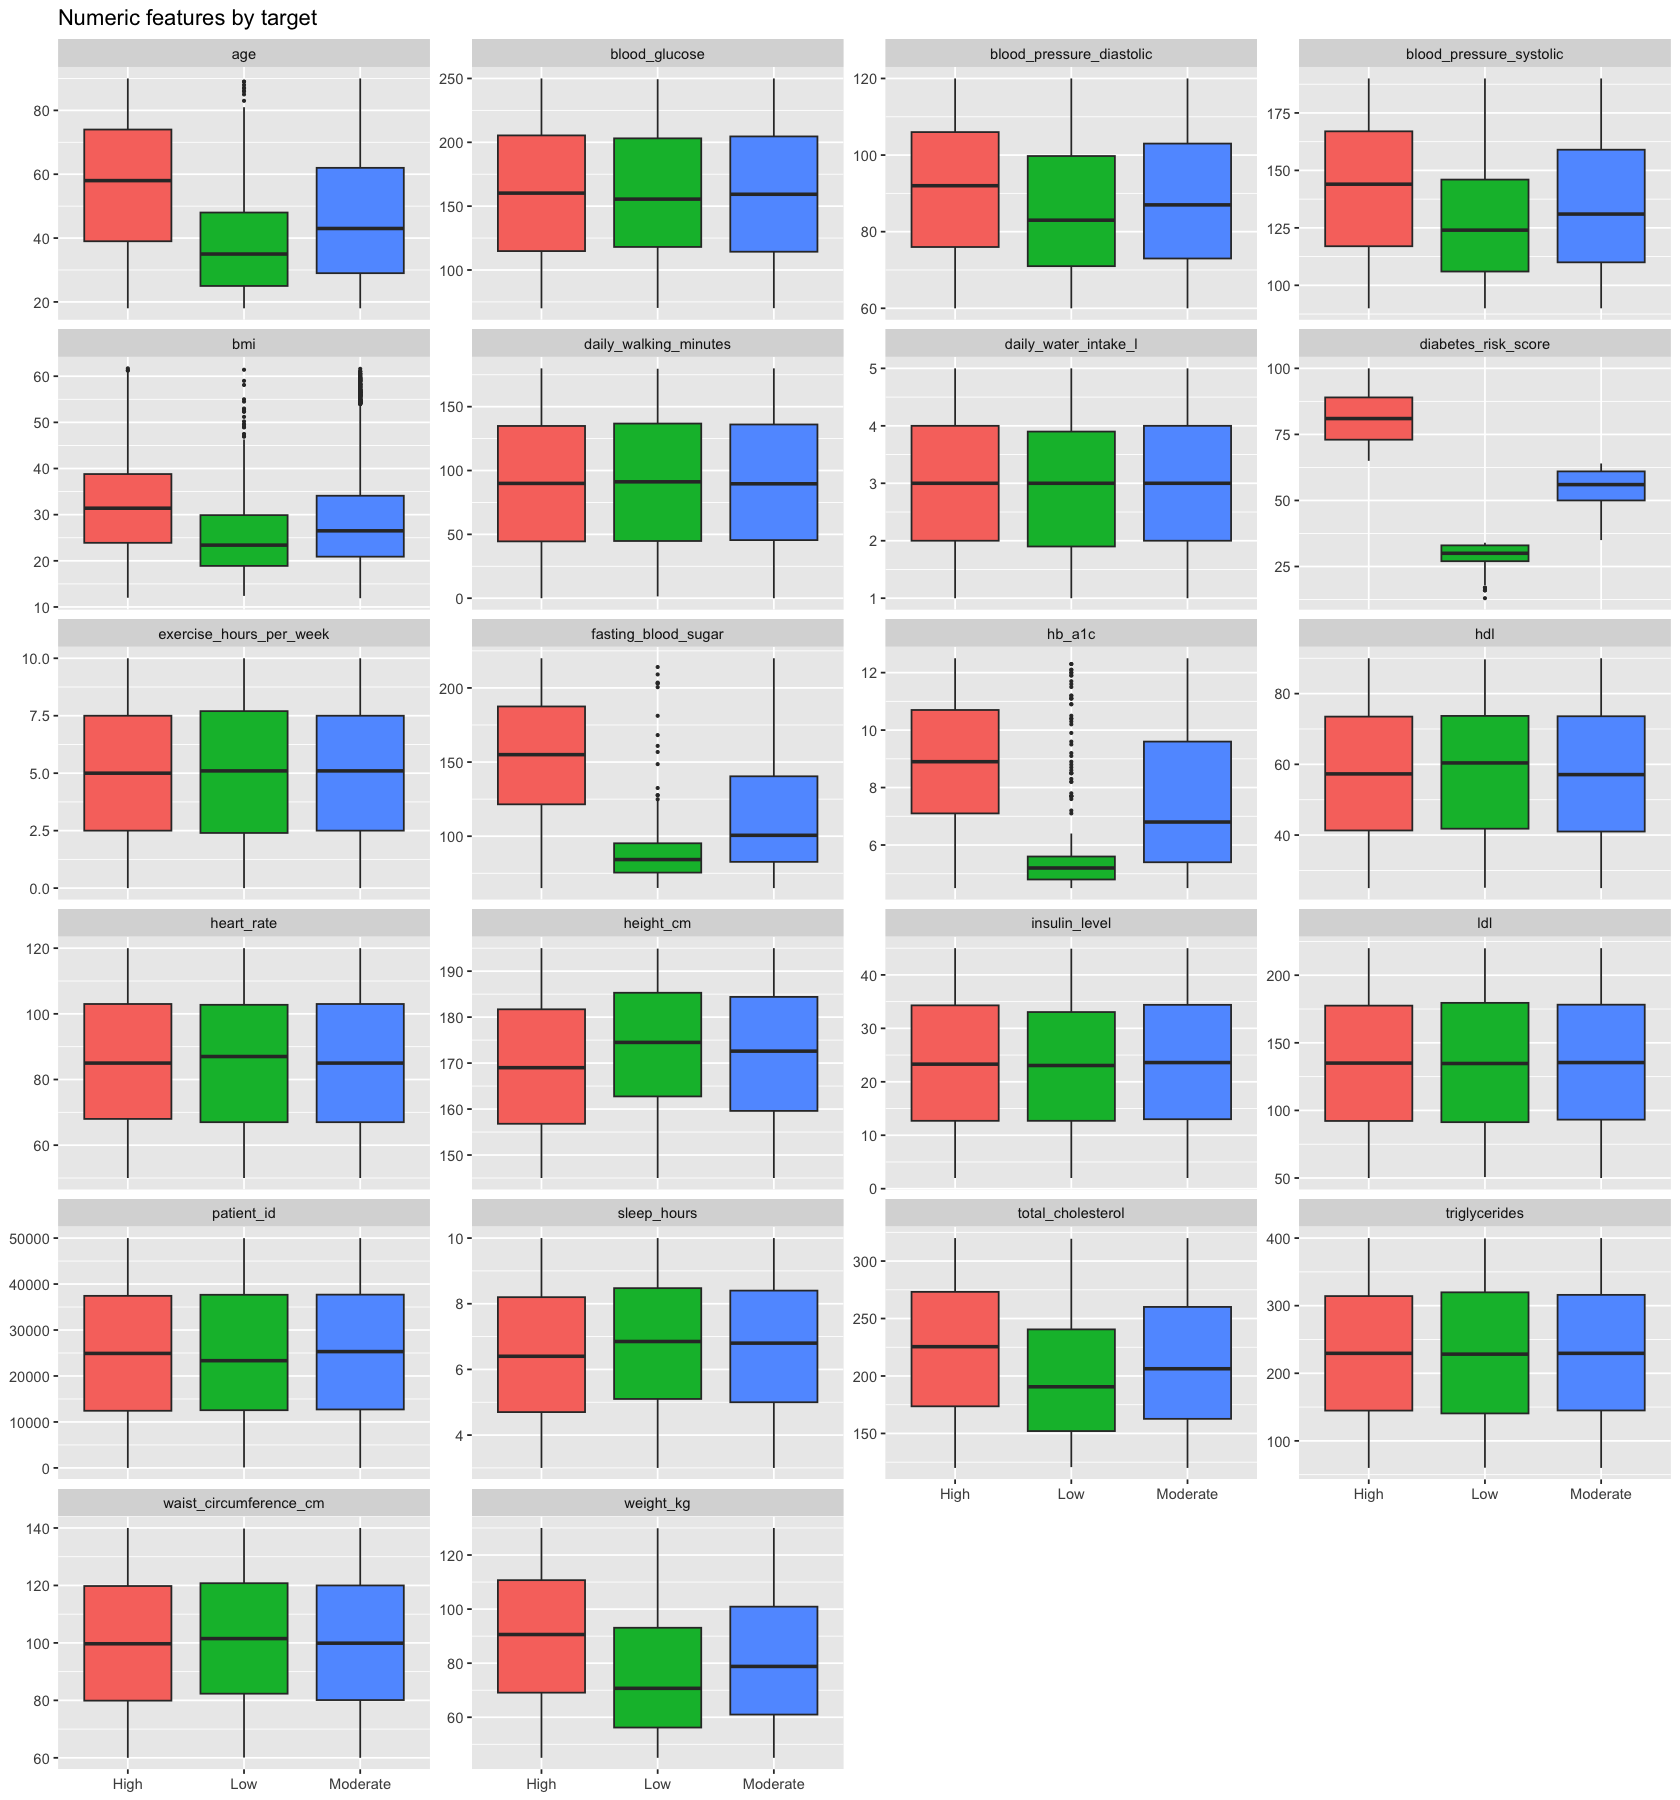

In [18]:
#boxplots for numeric columns
df |>
  select(all_of(c(target, num_cols))) |>
  pivot_longer(-all_of(target), names_to = "feature", values_to = "value") |>
  ggplot(aes(x = .data[[target]], y = value, fill = .data[[target]])) +
  geom_boxplot(outlier.size = 0.5, show.legend = FALSE) +
  facet_wrap(~ feature, scales = "free_y", ncol = 4) +
  labs(title = "Numeric features by target", x = NULL, y = NULL)

#### Numeric Features by Target (Boxplots)

**Observations**
- **`diabetes_risk_score` separates the classes almost perfectly.** The ranges barely overlap (Low about 27-33, Moderate about 50-62, High about 73-89). It is almost certainly derived from the target, so it is a **data leakage** risk.
- **`hb_a1c` and `fasting_blood_sugar` are the strongest genuine predictors.** High has the highest values, Moderate sits in between, and Low is tightly clustered at the bottom. Low has many high outliers, so a few Low patients have high values, which suggests noise in how the data was generated.
- **Moderate effects** appear in `age`, `bmi`, `weight_kg`, `blood_pressure_systolic`, `blood_pressure_diastolic` and `total_cholesterol`. The High group has higher medians than Low, but the boxes overlap heavily.
- **Slight effects** appear in `height_cm`, `sleep_hours` and `waist_circumference_cm`: Low has slightly higher medians than High. Height and weight likely move together.
- **No visible difference** across classes for `blood_glucose`, `insulin_level`, `hdl`, `ldl`, `triglycerides`, `heart_rate`, `exercise_hours_per_week`, `daily_walking_minutes`, `daily_water_intake_l` and `patient_id`.
- `blood_glucose` showing no difference while `fasting_blood_sugar` and `hb_a1c` differ strongly suggests the target was built from a specific subset of columns rather than from clinically realistic relationships.

**Next steps**
- **Drop `patient_id`**, since it carries no signal.
- **Remove `diabetes_risk_score`** from the features, or train one model with it and one without, and report both. With it, accuracy will look near-perfect and mean little.
- **Keep** `hb_a1c`, `fasting_blood_sugar`, `age`, `bmi`, `weight_kg`, the blood pressure columns and `total_cholesterol` as the core features.
- **Test the flat features** with Kruskal-Wallis and effect size before dropping any, and use feature importance from the model to confirm.
- **Check combinations.** A weak feature alone can matter in an interaction (e.g. BMI with age), so tree-based models are worth including.
- **Handle the outliers** in `hb_a1c`, `fasting_blood_sugar` and `bmi` by keeping them, since they look genuine, and relying on tree models or scaling that tolerates them.
- **Reorder the x-axis** to Low, Moderate, High with `factor(..., levels = c("Low", "Moderate", "High"))` so the trend reads left to right.

In [20]:
install.packages("tibble", repos = "https://cloud.r-project.org")   


The downloaded binary packages are in
	/var/folders/_r/w52qnsrn2g303dmlc8vv14nr0000gn/T//RtmpesfO1Q/downloaded_packages


,Var1,Var2,Freq
,<fct>,<fct>,<dbl>
1,bmi,weight_kg,0.8434275
2,bmi,height_cm,-0.5161505
3,diabetes_risk_score,fasting_blood_sugar,0.4524529
4,diabetes_risk_score,hb_a1c,0.3176425
5,diabetes_risk_score,age,0.2789184
6,diabetes_risk_score,bmi,0.2256048
7,diabetes_risk_score,weight_kg,0.2056152
8,diabetes_risk_score,blood_pressure_systolic,0.1611095
9,diabetes_risk_score,total_cholesterol,0.1240183


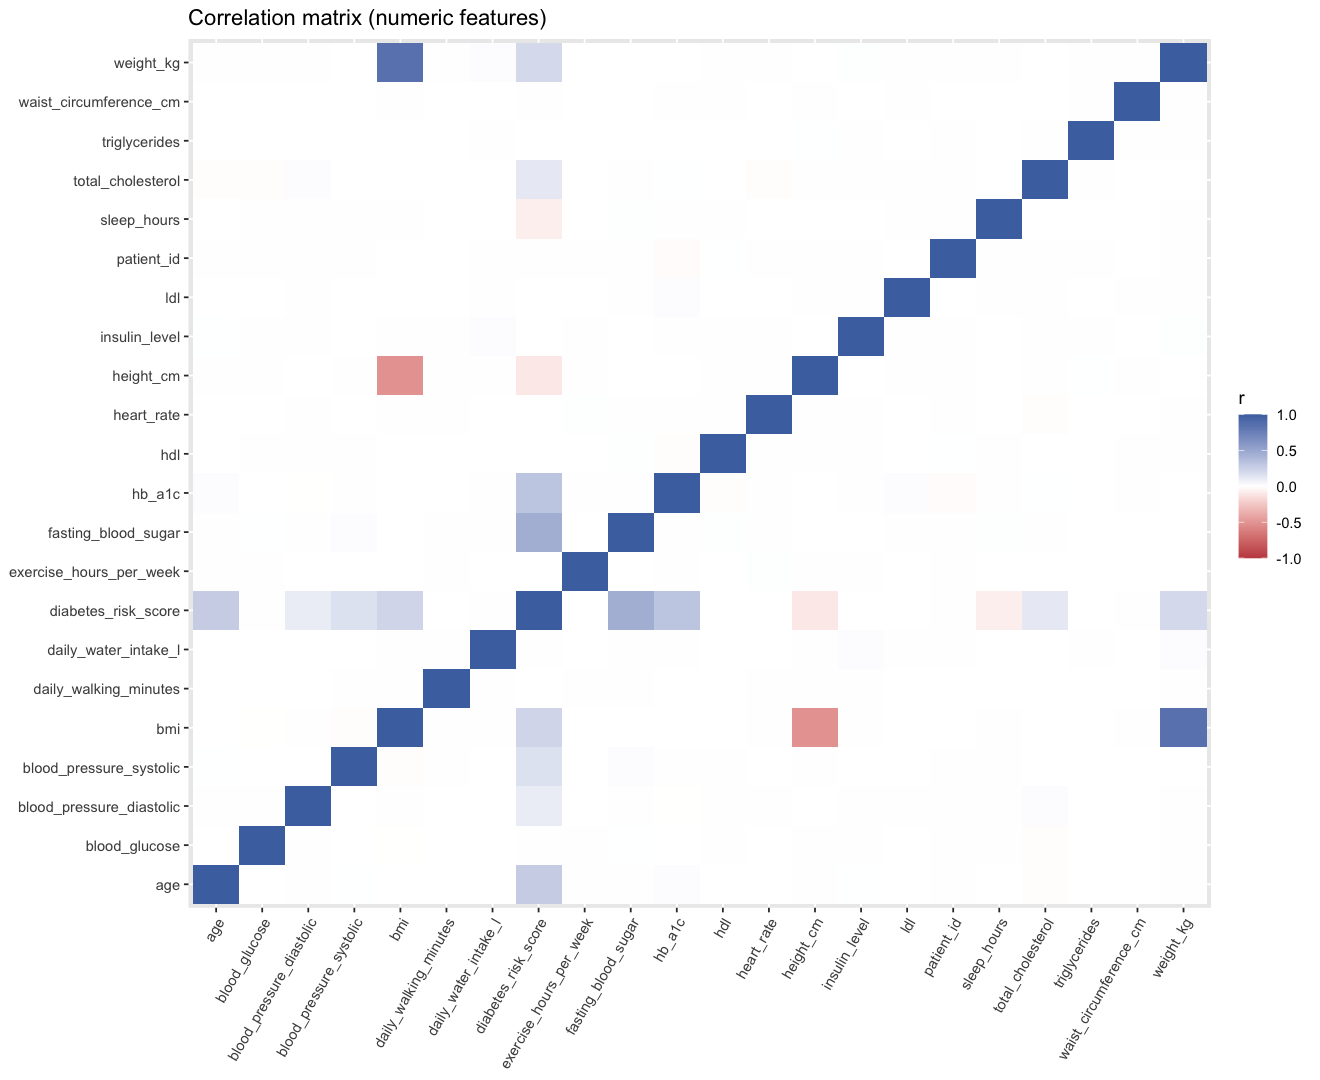

In [21]:
library(tibble)   
library(tidyr)
library(dplyr)
library(ggplot2)
#correlation heatmap (pearson correlation))
options(repr.plot.width = 11, repr.plot.height = 9)

cor_mat <- cor(df |> select(all_of(num_cols)), use = "pairwise.complete.obs")

cor_mat |>
  as.data.frame() |>
  rownames_to_column("x") |>
  pivot_longer(-x, names_to = "y", values_to = "r") |>
  ggplot(aes(x, y, fill = r)) +
  geom_tile() +
  scale_fill_gradient2(low = "#c44e52", mid = "white", high = "#4c72b0", limits = c(-1, 1)) +
  labs(title = "Correlation matrix (numeric features)", x = NULL, y = NULL, fill = "r") +
  theme(axis.text.x = element_text(angle = 60, hjust = 1))

# Strongest pairs
cor_mat[upper.tri(cor_mat, diag = TRUE)] <- NA
as.data.frame(as.table(cor_mat)) |>
  drop_na() |>
  arrange(desc(abs(Freq))) |>
  head(10)

#### Correlation with the Target

**Observations**
- Pearson and Spearman correlations between numeric features and the target are weak.
- Features are mostly uniform and appear independently generated, so strong linear or monotonic relationships are not expected.

**Next steps**
- Use Kruskal-Wallis with an effect size (epsilon-squared) to compare features across the three risk levels, since the target is categorical.
- Use Cramér's V for categorical features.
- Fit a tree-based model and check feature importance to capture non-linear and interaction effects.

In [ ]:
#encode categorical features using one hot encoding
#perform spearman correlation for categorical features (for ordinal cat cols) and Cramer's V for nominal categorical features

